# Machine Learning Model built

In this notebook we'll be doing a simple machine learning model using a linear regression function from scikit-learn.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df =pd.read_csv('../data/house_price_regression_dataset.csv')

In [11]:
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [12]:
df_filted = df[['Square_Footage', 'House_Price']].sort_values(by='Square_Footage', ascending=True)
df_filted.head()


,Square_Footage,House_Price
728,503,206042.351316
318,504,149743.499954
725,505,159121.465615
556,509,179398.433193
751,509,140538.083185


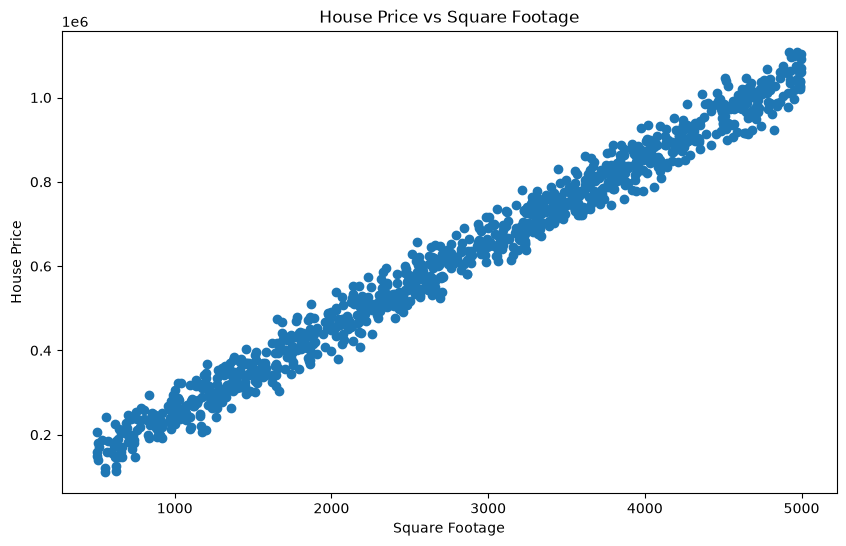

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    x=df_filted['Square_Footage'],
    y=df_filted['House_Price'],
)

ax.set_title('House Price vs Square Footage')
ax.set_xlabel('Square Footage')
ax.set_ylabel('House Price')
plt.show()

# Modeling using Scikit Learn

We'll be using a simple linear regresion from scikit learn. To do this we need to transform the actual dataframe to a 2d array.

### Fit model and generate predictions

In [18]:
# 1. Prepare the data
# X must be a 2D structure (DataFrame). Notice the double brackets [['...']]
X = df_filted[['Square_Footage']] 
# y is the target and can be a 1D structure (Series)
y = df_filted['House_Price']

# 2. Initialize and train (fit) the model
model = LinearRegression()
model.fit(X, y)

# 3. Generate predictions using the fitted model
df_filted['predicted_price'] = model.predict(X)

### Visualizations and evaluate performace

Equation: Price = (200.20 * Square_Footage) + 55217.67
R-squared: 0.9826


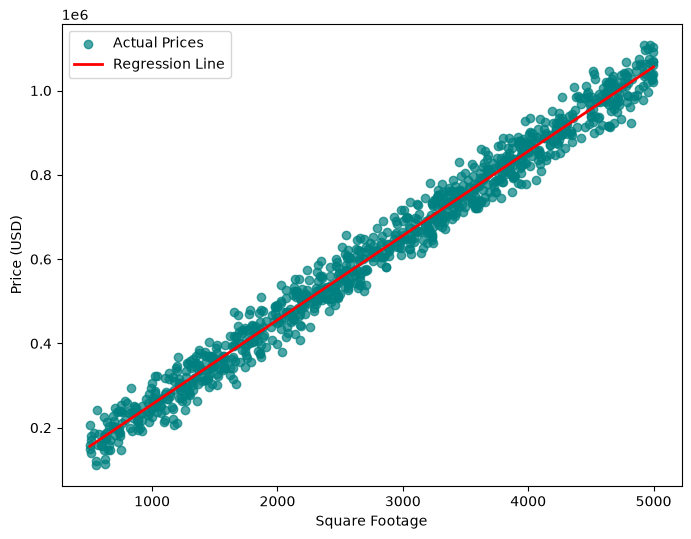

In [19]:
# 4. Evaluate the model
slope = model.coef_[0]
intercept = model.intercept_
r2 = r2_score(y, df_filted['predicted_price'])

print(f"Equation: Price = ({slope:.2f} * Square_Footage) + {intercept:.2f}")
print(f"R-squared: {r2:.4f}")

# Optional: Plot the actual data vs. the regression line
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X, y, color='teal', alpha=0.7, label='Actual Prices')
ax.plot(X, df_filted['predicted_price'], color='red', linewidth=2, label='Regression Line')
ax.set_xlabel('Square Footage')
ax.set_ylabel('Price (USD)')
ax.legend()
plt.show()

### Checking a single house price

In [20]:
# Using a Pandas DataFrame (Recommended to avoid feature name warnings)
# Use the exact same column name you used when fitting the model
single_house_df = pd.DataFrame({'Square_Footage': [2000]})
predicted_price = model.predict(single_house_df)

print(f"Predicted price for 2,000 sq ft: ${predicted_price[0]:,.2f}")


Predicted price for 2,000 sq ft: $455,614.73
